# DeepPCB — 단계별 EDA·전처리·CNN 학습

Python 3.11.9를 유지합니다. 기존 `deeppcb/data` 원본은 변경하지 않습니다. 노트북은 EDA, 그룹 분할·Crop, Metal 진단, CNN A/B 학습 순서로 구성됩니다.

- 라벨: `x1 y1 x2 y2 class_id` (원본 ID 1~6, 학습용 ID 0~5).
- 첫 EDA 절에서는 전체 수량·무결성만 감사하고 상세 분석은 trainval을 사용합니다.
- 공식 test는 잠그고 이후 Crop·모델 선택에 사용하지 않습니다.
- 학습 셀은 실제 학습을 실행합니다. 같은 설정의 완료 run은 재사용하고 로그/모델은 보존합니다.
- 결과는 `results/`, 학습 모델은 `models/`에 저장합니다. Softmax는 보정되지 않은 클래스 상대 점수입니다.

## 1단계 — 실제 데이터 확인 및 EDA

In [10]:
# 사용자 결정: 현재 Python 3.11.9 환경을 유지합니다.
import sys
import platform
from pathlib import Path
from importlib import metadata

ROOT = Path.cwd()
if not (ROOT / 'data').is_dir():
    raise RuntimeError('노트북 작업 경로를 DNN_project로 설정하세요.')
print('Python:', sys.version)
print('Executable:', sys.executable)
print('Platform:', platform.platform(), platform.machine())
for package in ['numpy', 'pandas', 'matplotlib', 'Pillow', 'seaborn', 'scikit-learn', 'tensorflow', 'tensorflow-metal', 'ipykernel']:
    try:
        print(f'{package}: {metadata.version(package)}')
    except metadata.PackageNotFoundError:
        print(f'{package}: 미설치')

Python: 3.11.9 (main, Aug 14 2024, 04:17:21) [Clang 18.1.8 ]
Executable: /Users/yeongjunna/DNN_project/venv/bin/python
Platform: macOS-26.5.1-arm64-64bit arm64
numpy: 2.0.2
pandas: 3.1.1
matplotlib: 3.11.2
Pillow: 13.0.0
seaborn: 미설치
scikit-learn: 1.6.1
tensorflow: 2.18.1
tensorflow-metal: 1.2.0
ipykernel: 7.4.0


In [11]:
# 한 번에 한 이미지씩 읽고 생성된 processed/split 산출물은 원본 집계에서 제외합니다.
import importlib
import src.eda
importlib.reload(src.eda)
from src.eda import CLASSES, audit_dataset, save_tables, make_figures, write_report
import pandas as pd
from IPython.display import display, Image as DisplayImage, Markdown

DATA_ROOT = ROOT / 'data'
OUTPUT_ROOT = ROOT / 'results'
SEED = 42

audit = audit_dataset(DATA_ROOT)
save_tables(audit, OUTPUT_ROOT)
print({key: audit.summary[key] for key in [
    'physical_image_files', 'physical_annotation_files', 'manifest_pairs',
    'parsed_objects', 'valid_objects', 'errors', 'warnings', 'split_pairs', 'split_objects'
]})
display(audit.issues if not audit.issues.empty else pd.DataFrame({'무결성': ['문제 없음']}))

trainval: 목록 확인 완료
test: 목록 확인 완료
{'physical_image_files': 3001, 'physical_annotation_files': 1500, 'manifest_pairs': 1500, 'parsed_objects': 10013, 'valid_objects': 10013, 'errors': 0, 'warnings': 1, 'split_pairs': {'trainval': 1000, 'test': 500}, 'split_objects': {'trainval': 6873, 'test': 3140}}


,severity,kind,source_id,detail
0,warning,unlisted_image,group90100/90100/90100034_temp.jpg,공식 목록에 없는 이미지


In [12]:
# 테스트 라벨은 수량 감사만 표시합니다. 모델 선택이나 증강 결정에 사용하지 않습니다.
class_counts = pd.read_csv(OUTPUT_ROOT / 'reports' / 'class_counts.csv')
display(class_counts)
display(pd.read_csv(OUTPUT_ROOT / 'reports' / 'group_split_counts.csv'))
print('공식 split 공통 그룹:', audit.summary['shared_official_groups'])
print('동일 픽셀 감사:', audit.summary['pixel_duplicates'])
print('대표 객체 레코드 (trainval):')
display(audit.objects.query("official_split == 'trainval'").head(6))

,class_id,target_id,class_name,korean,trainval,test,total
0,1,0,Open Circuit,회로 단선,1283,659,1942
1,2,1,Short Circuit,회로 단락,1028,478,1506
2,3,2,Mousebite,패턴 가장자리 결손,1379,586,1965
3,4,3,Spur,구리 돌출,1142,483,1625
4,5,4,Spurious Copper,잔여 구리,1010,464,1474
5,6,5,Pin Hole,패턴 내부 구멍,1031,470,1501


,group,official_split,image_pairs,objects
0,group00041,test,21,107
1,group00041,trainval,200,1535
2,group12000,test,14,93
3,group12100,test,146,919
4,group12300,test,98,600
5,group13000,test,18,106
6,group13000,trainval,198,1345
7,group20085,test,34,230
8,group20085,trainval,291,2198
9,group44000,test,50,369


공식 split 공통 그룹: ['group00041', 'group13000', 'group20085', 'group44000', 'group50600', 'group77000', 'group92000']
동일 픽셀 감사: {'test': {'repeated_hash_groups': 0, 'cross_split_hash_groups': 0, 'cross_split_images': 0}, 'temp': {'repeated_hash_groups': 1, 'cross_split_hash_groups': 0, 'cross_split_images': 0}}
대표 객체 레코드 (trainval):


,source_id,group,official_split,label_path,line_number,x1,y1,x2,y2,class_id,class_name,target_id,bbox_width,bbox_height,bbox_area,valid
0,group20085/20085/20085000,group20085,trainval,group20085/20085_not/20085000.txt,1,409,394,435,422,3,Mousebite,2,26,28,728,True
1,group20085/20085/20085000,group20085,trainval,group20085/20085_not/20085000.txt,2,275,383,319,417,3,Mousebite,2,44,34,1496,True
2,group20085/20085/20085000,group20085,trainval,group20085/20085_not/20085000.txt,3,8,163,36,191,4,Spur,3,28,28,784,True
3,group20085/20085/20085000,group20085,trainval,group20085/20085_not/20085000.txt,4,244,151,270,182,5,Spurious Copper,4,26,31,806,True
4,group20085/20085/20085000,group20085,trainval,group20085/20085_not/20085000.txt,5,338,519,364,543,6,Pin Hole,5,26,24,624,True
5,group20085/20085/20085000,group20085,trainval,group20085/20085_not/20085000.txt,6,476,460,502,481,4,Spur,3,26,21,546,True


In [13]:
# 오류가 있으면 그림을 만들지 않고 무결성 보고서부터 확인합니다.
if audit.summary['errors']:
    raise RuntimeError('results/reports/integrity_issues.csv를 확인하세요.')
figure_paths = make_figures(audit, OUTPUT_ROOT, seed=SEED)
print('저장한 그래프:', len(figure_paths))
for path in figure_paths:
    print(path.relative_to(ROOT))

저장한 그래프: 6
results/figures/class_distribution.png
results/figures/bbox_sizes_trainval.png
results/figures/pixels_and_objects_trainval.png
results/figures/group_class_distribution_trainval.png
results/figures/class_examples_trainval.png
results/figures/template_defect_annotations_trainval.png


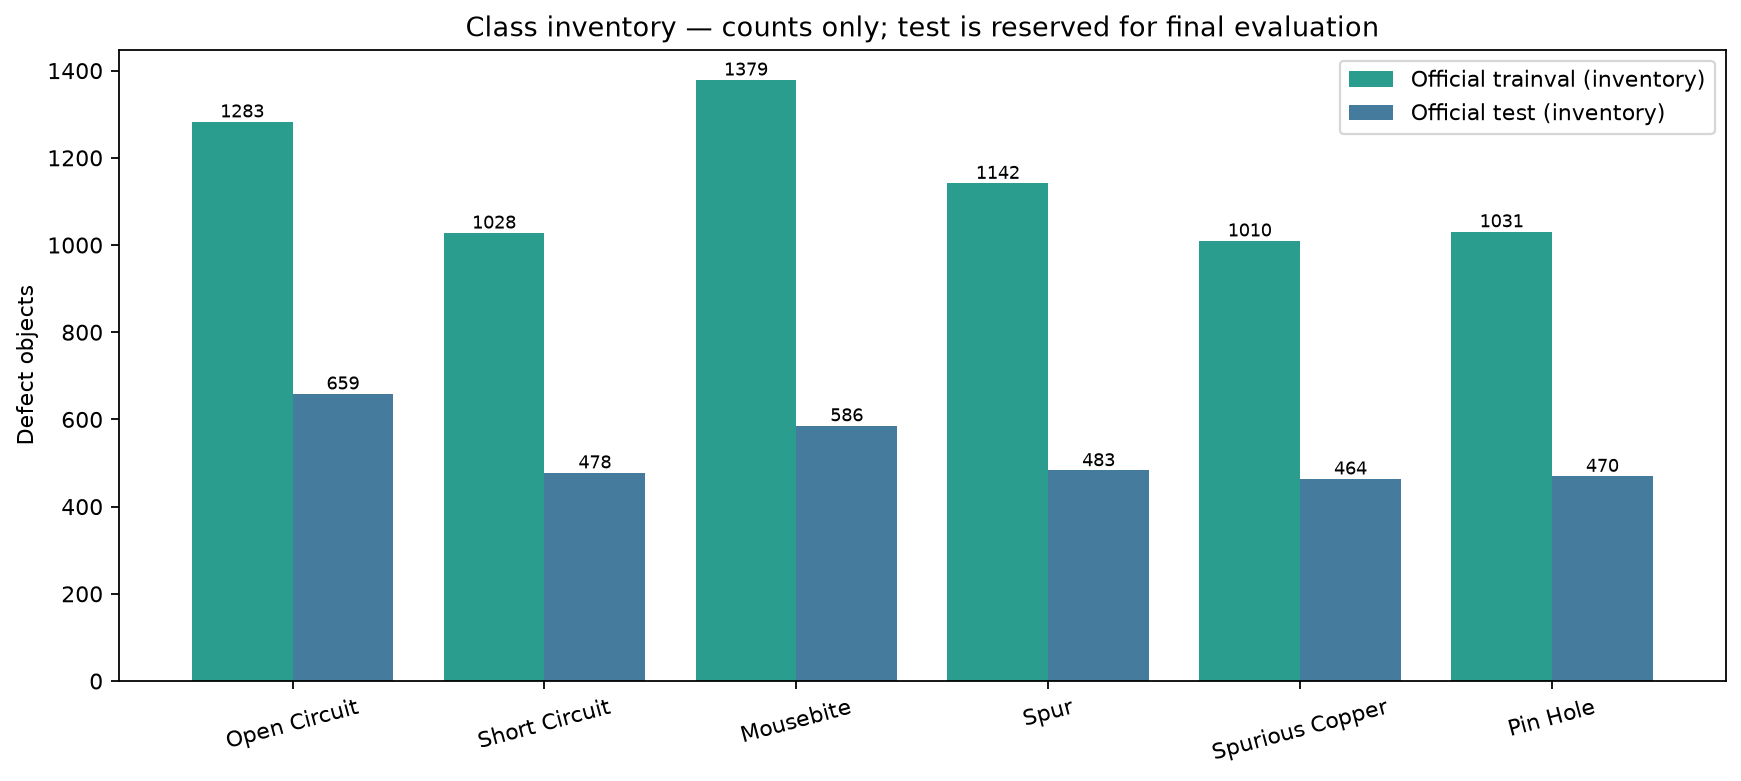

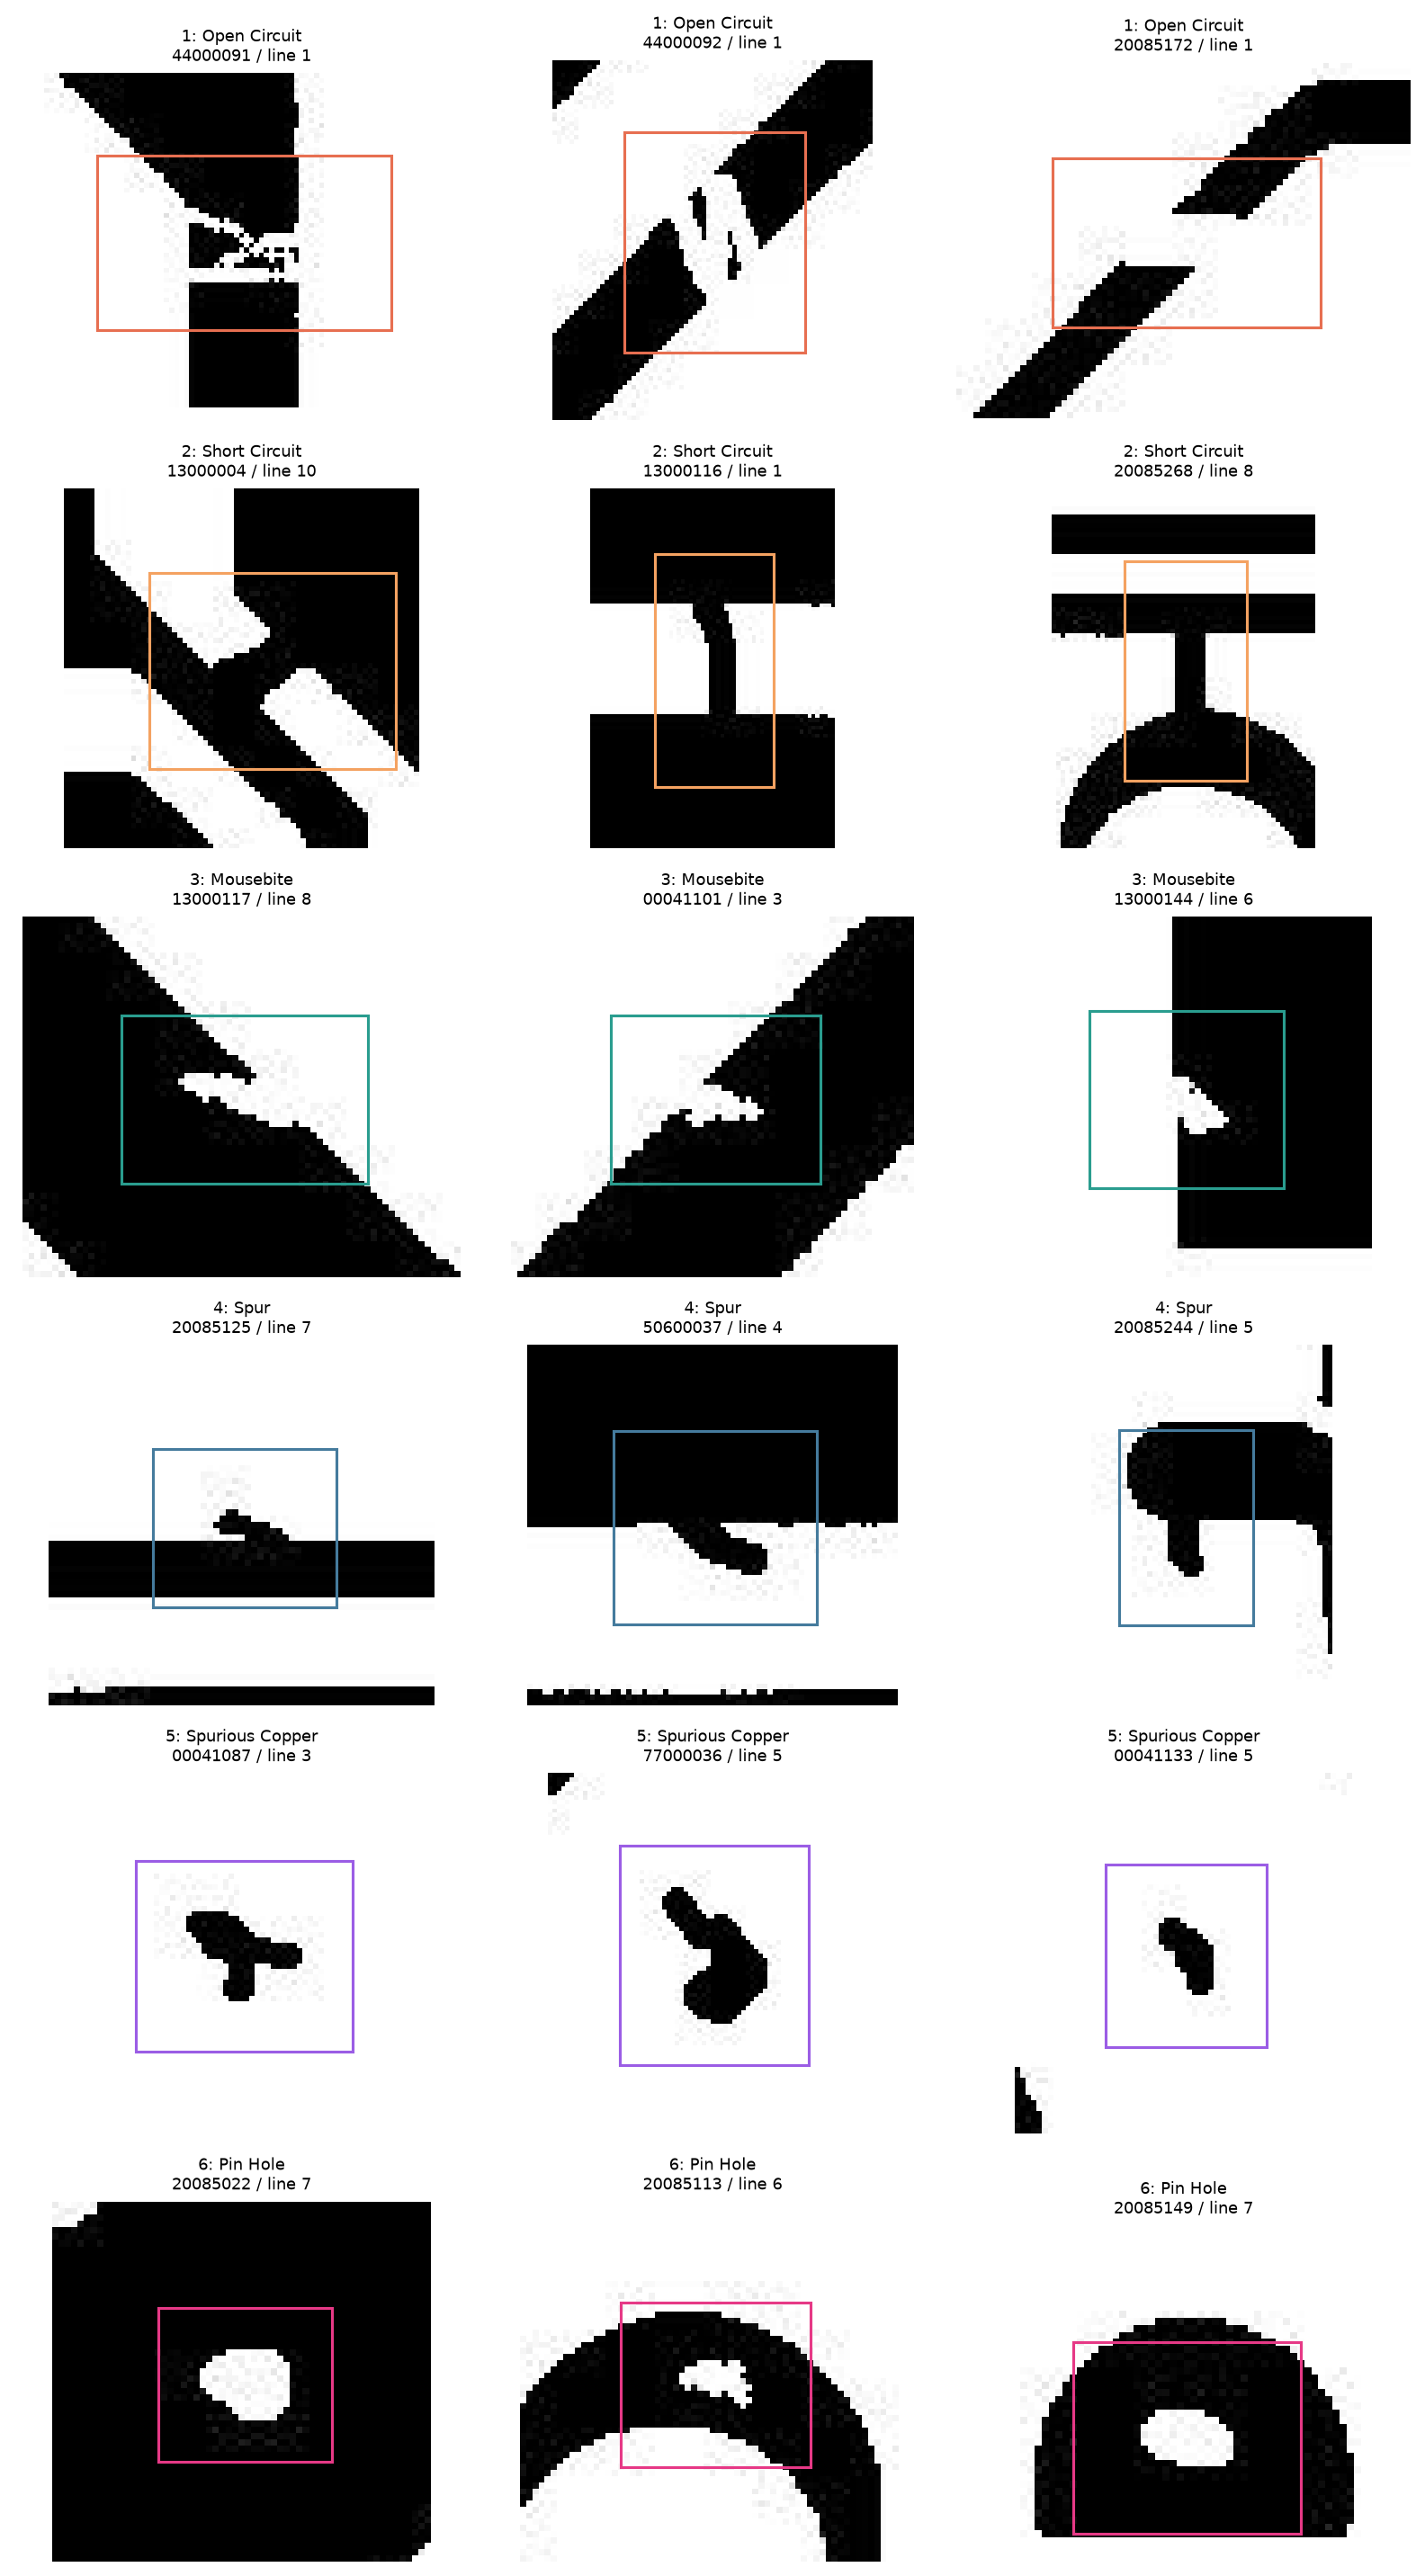

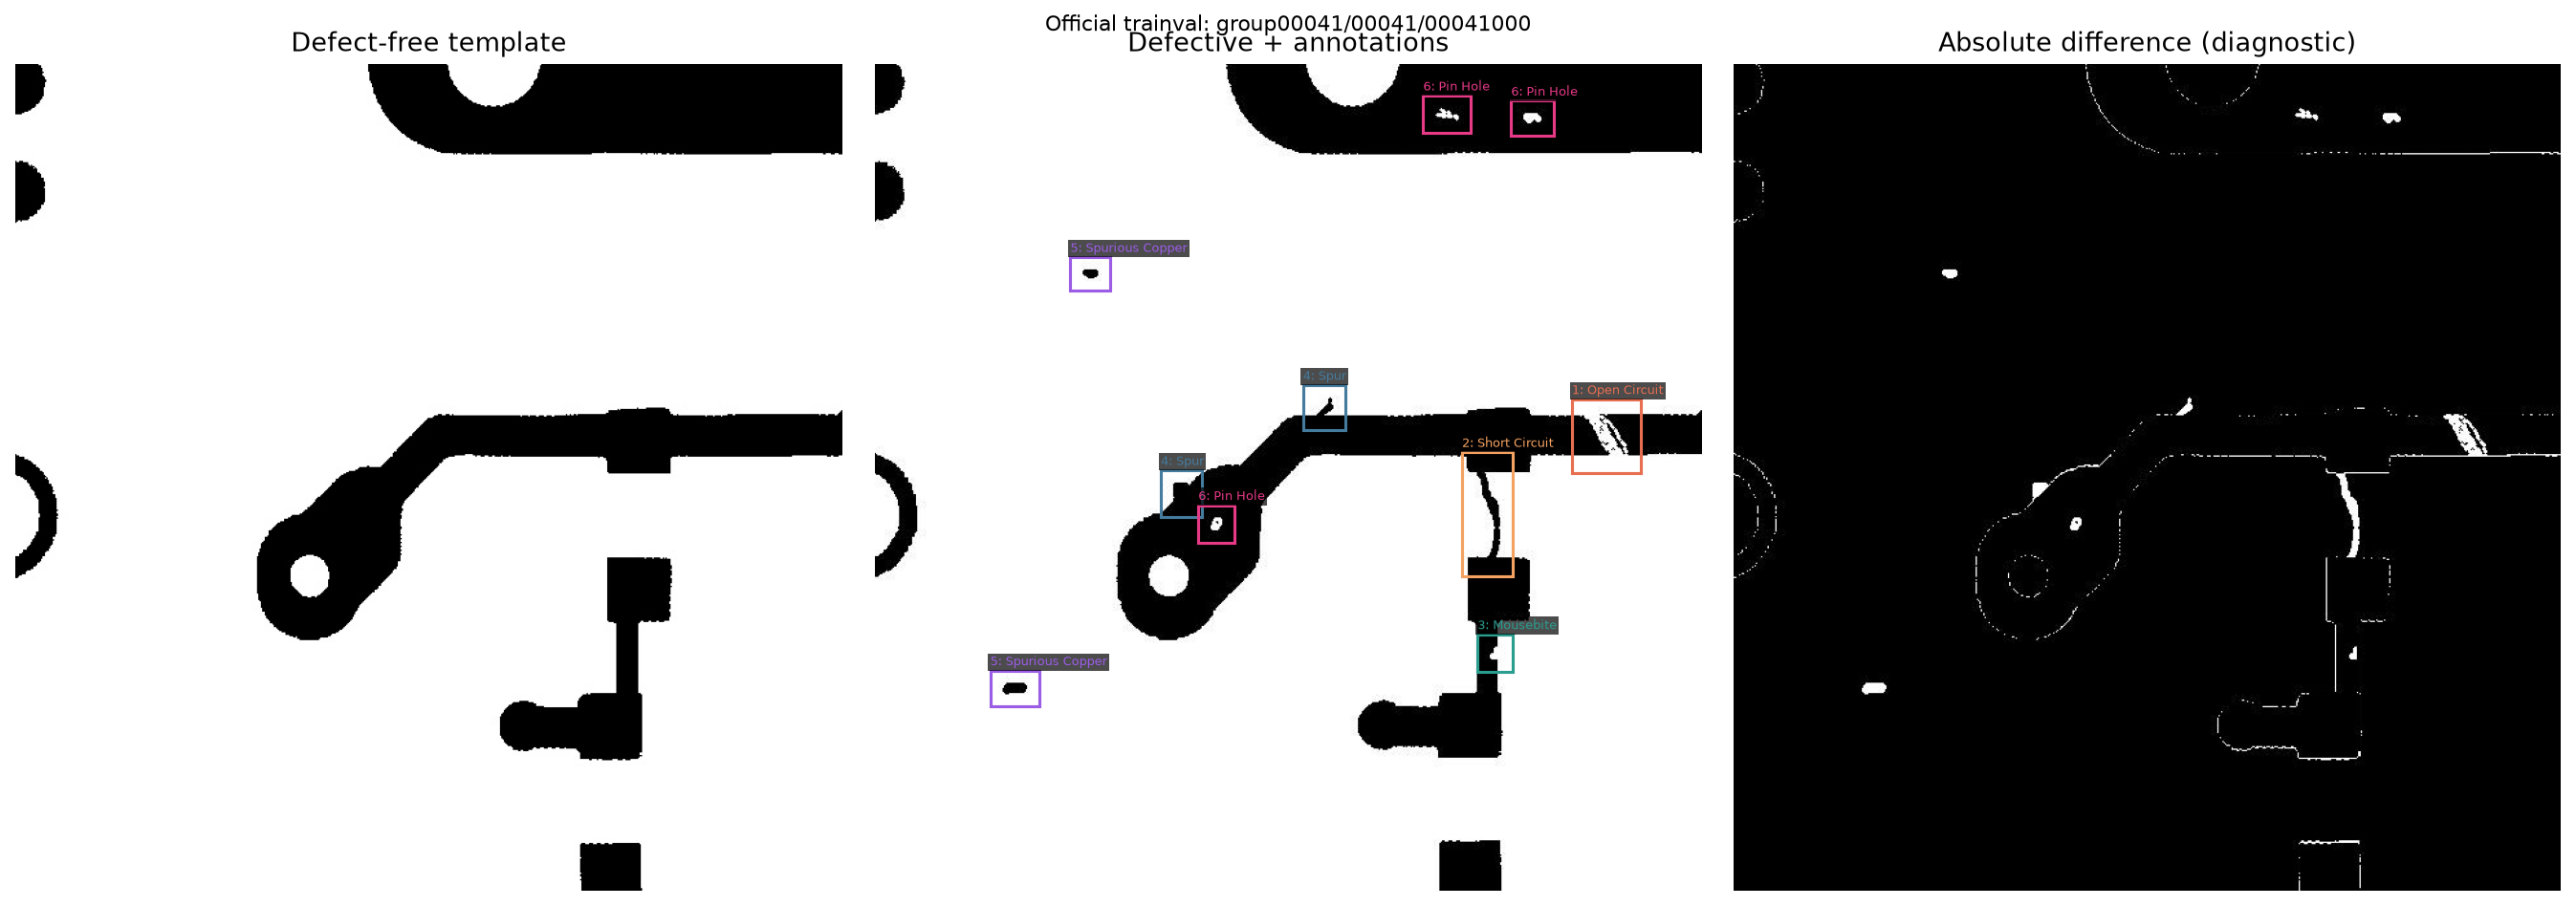

In [14]:
# 대표 예시와 정상/불량 쌍은 공식 trainval에서만 선택했습니다.
for filename in ['class_distribution.png', 'class_examples_trainval.png',
                 'template_defect_annotations_trainval.png']:
    display(DisplayImage(filename=str(OUTPUT_ROOT / 'figures' / filename), width=1000))

In [15]:
# 보고서에는 실측 결과와 아직 실행하지 않은 전처리 계획을 구분해 기록합니다.
report_path = write_report(audit, OUTPUT_ROOT)
display(Markdown(report_path.read_text(encoding='utf-8')))

# DeepPCB 데이터 확보 및 EDA 결과

생성 시각(UTC): 2026-11-18T06:19:24.451357+00:00

## 1. 실제 파일과 라벨

- 데이터 루트: `/Users/yeongjunna/DNN_project/data`. 다운로드는 수행하지 않았고 기존 파일을 사용했다.
- 디스크 이미지 **3,001개**, 주석 파일 **1,500개**.
- 목록의 이미지 쌍 **1,500개** = 검사 영상 + 정상 기준 영상.
- 목록에 연결된 실제 이미지 **3,000개**. 목록 외 이미지: `group90100/90100/90100034_temp.jpg`.
  목록 외 파일은 자동 포함/삭제하지 않고 학습 후보에서 제외한다.
- 공식 trainval **1,000쌍**, test **500쌍**.
- 라벨 비어 있지 않은 행 **10,013개**, 파싱 객체 **10,013개**, 유효 객체 **10,013개**.
- 오류 **0건**, 경고 **1건**. 세부 내역은 `integrity_issues.csv` 참조.
- 검사 영상 해상도/모드: `{"(640, 640, 'L')": 1462, "(640, 640, 'RGB')": 38}`.
- 기준 영상 해상도/모드: `{"(640, 640, 'L')": 1476, "(640, 640, 'RGB')": 24}`.
- trainval 검사 영상 중 RGB 저장 형식은 **22개**이며 이 파일의 최대 채널 간 차이는
  **0**이다. 파일 모드가 혼재하므로 로딩 시 grayscale 변환 규칙을 명시한다.

```text
data/
  trainval.txt / test.txt
  group00041/
    00041/00041000_test.jpg   # 불량 검사 영상
    00041/00041000_temp.jpg   # 정렬된 정상 기준 영상
    00041_not/00041000.txt    # 검사 영상 안의 모든 객체
  ...
```

목록 한 행은 이미지 참조 경로와 라벨 경로 2개다. 참조 `00041000.jpg`는
실제 `_test.jpg`와 `_temp.jpg`에 연결해야 한다. 주석 한 행은 공백으로 구분된
`x1 y1 x2 y2 class_id`이며 YOLO 정규화 좌표 형식이 아니다.
원본 ID `1~6`은 모델 학습 시 `0~5`로 변환하되 매핑을 모델과 함께 저장해야 한다.

## 2. 클래스 분포

| ID | 유형 | trainval 객체 | test 객체 (수량 감사) | 전체 |
|---:|---|---:|---:|---:|
| 1 | Open Circuit (회로 단선) | 1,283 | 659 | 1,942 |
| 2 | Short Circuit (회로 단락) | 1,028 | 478 | 1,506 |
| 3 | Mousebite (패턴 가장자리 결손) | 1,379 | 586 | 1,965 |
| 4 | Spur (구리 돌출) | 1,142 | 483 | 1,625 |
| 5 | Spurious Copper (잔여 구리) | 1,010 | 464 | 1,474 |
| 6 | Pin Hole (패턴 내부 구멍) | 1,031 | 470 | 1,501 |

trainval의 최대/최소 클래스 수 비율: **1.365**.
이 비율과 클래스별 검증 Recall을 바탕으로 이후 class weight 필요성을 판단한다.
공식 test의 라벨은 수량/무결성 감사에만 읽었으며, 예시 이미지·크기·픽셀 분석 및
하이퍼파라미터 선택에는 사용하지 않았다.

## 3. 학습 후보(trainval)의 객체 크기

아래는 `x2-x1`, `y2-y1` 기준 좌표 범위 통계다. 원본 주석의 끝점 포함 여부는
아직 확정하지 않았으며 실제 Crop 규약은 다음 단계에서 고정한다.

```text
quantile       width    height      area
      bbox_width  bbox_height  bbox_area
0.00        20.0         19.0      400.0
0.25        31.0         28.0      960.0
0.50        35.0         33.0     1188.0
0.75        42.0         39.0     1584.0
0.95        68.0         57.0     3069.8
1.00       173.0        152.0    16750.0
```

이미지별 객체 수: 최소 1,
중앙값 7.0, 최대 15.
픽셀값 분포는 `pixel_histogram_trainval.csv` 및 그래프로 저장했다. 이미 이진화에 가까운
영상이므로 밝기 증강은 일반 사진과 다르게 소량만 검증하고 과도한 재이진화는 피한다.
trainval 검사 영상에서 0~15 또는 240~255 범위인 픽셀은 **99.32%**다.

## 4. 분할과 누수 위험

- 디렉터리 그룹 **11개**. 공식 trainval/test 공통 그룹 **7개**:
  `group00041, group13000, group20085, group44000, group50600, group77000, group92000`.
- L 변환 픽셀 해시 감사: `{'test': {'repeated_hash_groups': 0, 'cross_split_hash_groups': 0, 'cross_split_images': 0}, 'temp': {'repeated_hash_groups': 1, 'cross_split_hash_groups': 0, 'cross_split_images': 0}}`.
- 상세한 그룹별 수량은 `group_split_counts.csv`, 중복 픽셀 목록은 `duplicate_pixels_*.csv`에 저장했다.
- 동일 검사 이미지의 patch를 무작위 분할하면 누수가 발생한다. **원본 이미지 단위로 먼저 분할**해야 한다.
- 디렉터리 그룹은 촬영/기판 그룹의 후보이며 실제 기판 식별자라는 보장은 없다.
  공식 test는 그대로 보존하되 공통 그룹이 있으면 '미관측 기판 일반화' 성능으로 해석할 수 없다.
- trainval 내부에서 그룹 전체를 검증용으로 홀드아웃하는 방식을 우선 검토한다.
  모든 클래스가 포함되는지와 검증 규모를 trainval만으로 확인한 뒤 seed/그룹 목록을 고정한다.
- trainval에서 6종 객체가 모두 관측된 그룹: `group00041, group13000, group20085, group44000, group50600, group77000, group92000`.
  trainval의 20%에 가장 가까운 검증용 그룹 후보는 `group00041` (200쌍), `group13000` (198쌍)이며,
  최종 그룹은 템플릿 유사도와 클래스 분포를 확인한 후 선택한다. 아직 분할하지 않았다.
- 정확한 픽셀 해시는 유사/인접 타일의 중복을 증명하거나 배제하지 않는다.
  다음 단계에서 trainval의 그룹/템플릿 유사도를 조사하고 필요 시 연결 그룹을 함께 분할한다.

## 5. 다음 단계 전처리 계획 (미실행)

1. 무결성 오류가 있으면 원본을 자동 수정하지 말고 원인과 처리 방침부터 기록한다.
2. trainval 원본에 train/validation을 먼저 배정하고 공식 test를 잠근 manifest를 저장한다.
3. 각 객체 중심 주변에 여백을 둔 정사각 ROI를 만든다. 우선 16px 또는 bbox 비례 여백을
   trainval 예시로 비교하고, 영상 경계와 주변 불량이 함께 포함되는 비율을 조사한다.
   이웃 불량이 들어오면 주 불량 ID와 포함 여부를 남겨 단일 라벨 모호성을 관리한다.
4. 좌표 규약을 명시하고 영상 밖 여백은 padding한다. 종횡비를 보존해 128×128로 맞춘다.
   PNG 등 무손실로 저장하며 source_id, group, split, class_id, 좌표, 여백 설정을 함께 저장한다.
5. Model A/B는 단일 grayscale 채널을 우선 사용한다. 0~1 정규화는 로딩 시 수행하고
   데이터셋 전체를 float32 배열로 메모리에 올리지 않는다. tf.data에서 batch 16으로 시작한다.
6. 증강은 train만 적용한다. 90도 회전/좌우/상하 반전부터 시작하고 미세 회전/밝기/확대는
   불량이 잘리거나 보간으로 사라지지 않는지 확인한다. validation/test는 변형하지 않는다.
7. A/B 구조와 검증 성능을 먼저 비교한다. Model C는 grayscale을 RGB로 복제하고
   선택한 백본의 preprocess_input 규약을 사용해 이중 정규화를 피한다.
8. 분할과 모델 선택은 validation Macro F1로 수행하고 공식 test는 최종 확정 후 한 번 평가한다.
   Macro F1 0.90은 목표이며 현재 측정한 성능은 없다.

이 보고서는 1단계 EDA 범위만 다룬다. 후속 전처리/학습 실행 상태는
`preprocessing_summary.json`과 모델별 학습 보고서에서 확인한다.
여기서 제시한 대표 이미지의 Crop은 시각화 전용이며 학습 데이터 파일이 아니다.

## 6. 환경

사용자 결정에 따라 기존 Python **3.11.9** 환경을 유지했다.
실제 설치 버전과 아키텍처는 `environment.json`에 기록했다. EDA 함수에서는
GPU 런타임을 검증하지 않는다. 학습 단계의 실제 검증은 별도 보고서를 확인한다.
Apple Silicon의 TensorFlow 가속은 `tensorflow-metal`
PluggableDevice를 사용하며 PyTorch의 `mps` 설정과 구분한다.
학습 단계에서 패키지 호환성을 확인하고 작은 tensor 연산 및 GPU 열거를 실제 실행해야 한다.

## 출처

- [DeepPCB 공식 README: 구조·ID·생성 방식](https://github.com/tangsanli5201/DeepPCB)
- [TensorFlow 설치 및 Python 지원](https://www.tensorflow.org/install/pip)
- [Apple tensorflow-metal 설치/제한](https://developer.apple.com/metal/tensorflow-plugin/)

DeepPCB에는 인공적으로 추가한 불량이 포함된다. 본 Crop 분류 결과를 실제 생산 데이터의
전수 검사 성능이나 원본 영상의 자동 탐지 성능으로 해석할 수 없다. 공식 문서의 연구 목적
사용 안내도 후속 활용 전에 확인한다.


## 2단계 — 그룹 분할 및 불량 패치 전처리

Python 3.11.9를 유지하며 TensorFlow 2.18.1, Metal 1.2.0, Keras 3.8.0, NumPy 2.0.2를 설치했습니다. 패키지 변경 후 커널을 다시 시작했습니다.

- 검증 그룹은 trainval 이미지 수의 20%에 가장 가까운 `group00041`로 **학습 전에** 고정합니다.
- 공식 test는 전처리/모델 선택에 사용하지 않고 최종 평가 전까지 Crop도 생성하지 않습니다.
- 각 불량의 정사각 ROI에 16px 문맥을 추가하고, 인접 불량 포함 여부를 기록합니다.
- 목표 지표는 검증 Macro F1이며, 최종 test Macro F1 0.90은 미달 가능성이 있는 목표입니다.

In [16]:
# GPU 열거와 실제 연산을 확인합니다. 작은 연산의 성공과 전체 학습 검증을 구분합니다.
import tensorflow as tf
import numpy as np
from pathlib import Path
import json

ROOT = Path.cwd()
print('TensorFlow:', tf.__version__, 'NumPy:', np.__version__)
gpus = tf.config.list_physical_devices('GPU')
print('GPU:', gpus)
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass
with tf.device('/GPU:0' if gpus else '/CPU:0'):
    probe = tf.reduce_sum(tf.matmul(tf.ones((32, 32)), tf.ones((32, 32))))
print('실제 연산:', probe.numpy(), probe.device)
assert float(probe.numpy()) == 32768.0
(ROOT / 'results/reports/hardware_probe.json').write_text(json.dumps({
    'tensorflow': tf.__version__, 'gpus': [str(gpu) for gpu in gpus],
    'actual_device': probe.device, 'matmul_sum': float(probe.numpy()),
    'note': 'Matrix smoke test only. See metal_diagnostic.json and metal_workaround.json for graph correctness.'
}, indent=2))

TensorFlow: 2.18.1 NumPy: 2.0.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
실제 연산: 32768.0 /job:localhost/replica:0/task:0/device:GPU:0


320

전처리 완료: {'config': {'size': 128, 'margin': 16, 'validation_group': 'group00041', 'seed': 42, 'endpoint': 'inclusive_conservative', 'padding': 'edge', 'interpolation': 'bilinear'}, 'source_counts': {'train': 800, 'test': 500, 'val': 200}, 'patch_counts': {'train': 5338, 'val': 1535}, 'neighbor_patches': 1136, 'padded_patches': 264, 'cross_split_exact_patch_duplicates': 0, 'cross_split_group_overlap': 0, 'test_patches_created': 0, 'manifest_sha256': '403019c76cb1995b420781e6b2f95aa4709adb10229c4ac68f4a78cc981284a9'}


split,train,val
class_name,,
Mousebite,1032,347
Open Circuit,1005,278
Pin Hole,810,221
Short Circuit,825,203
Spur,888,254
Spurious Copper,778,232


테스트 패치 생성 수: 0


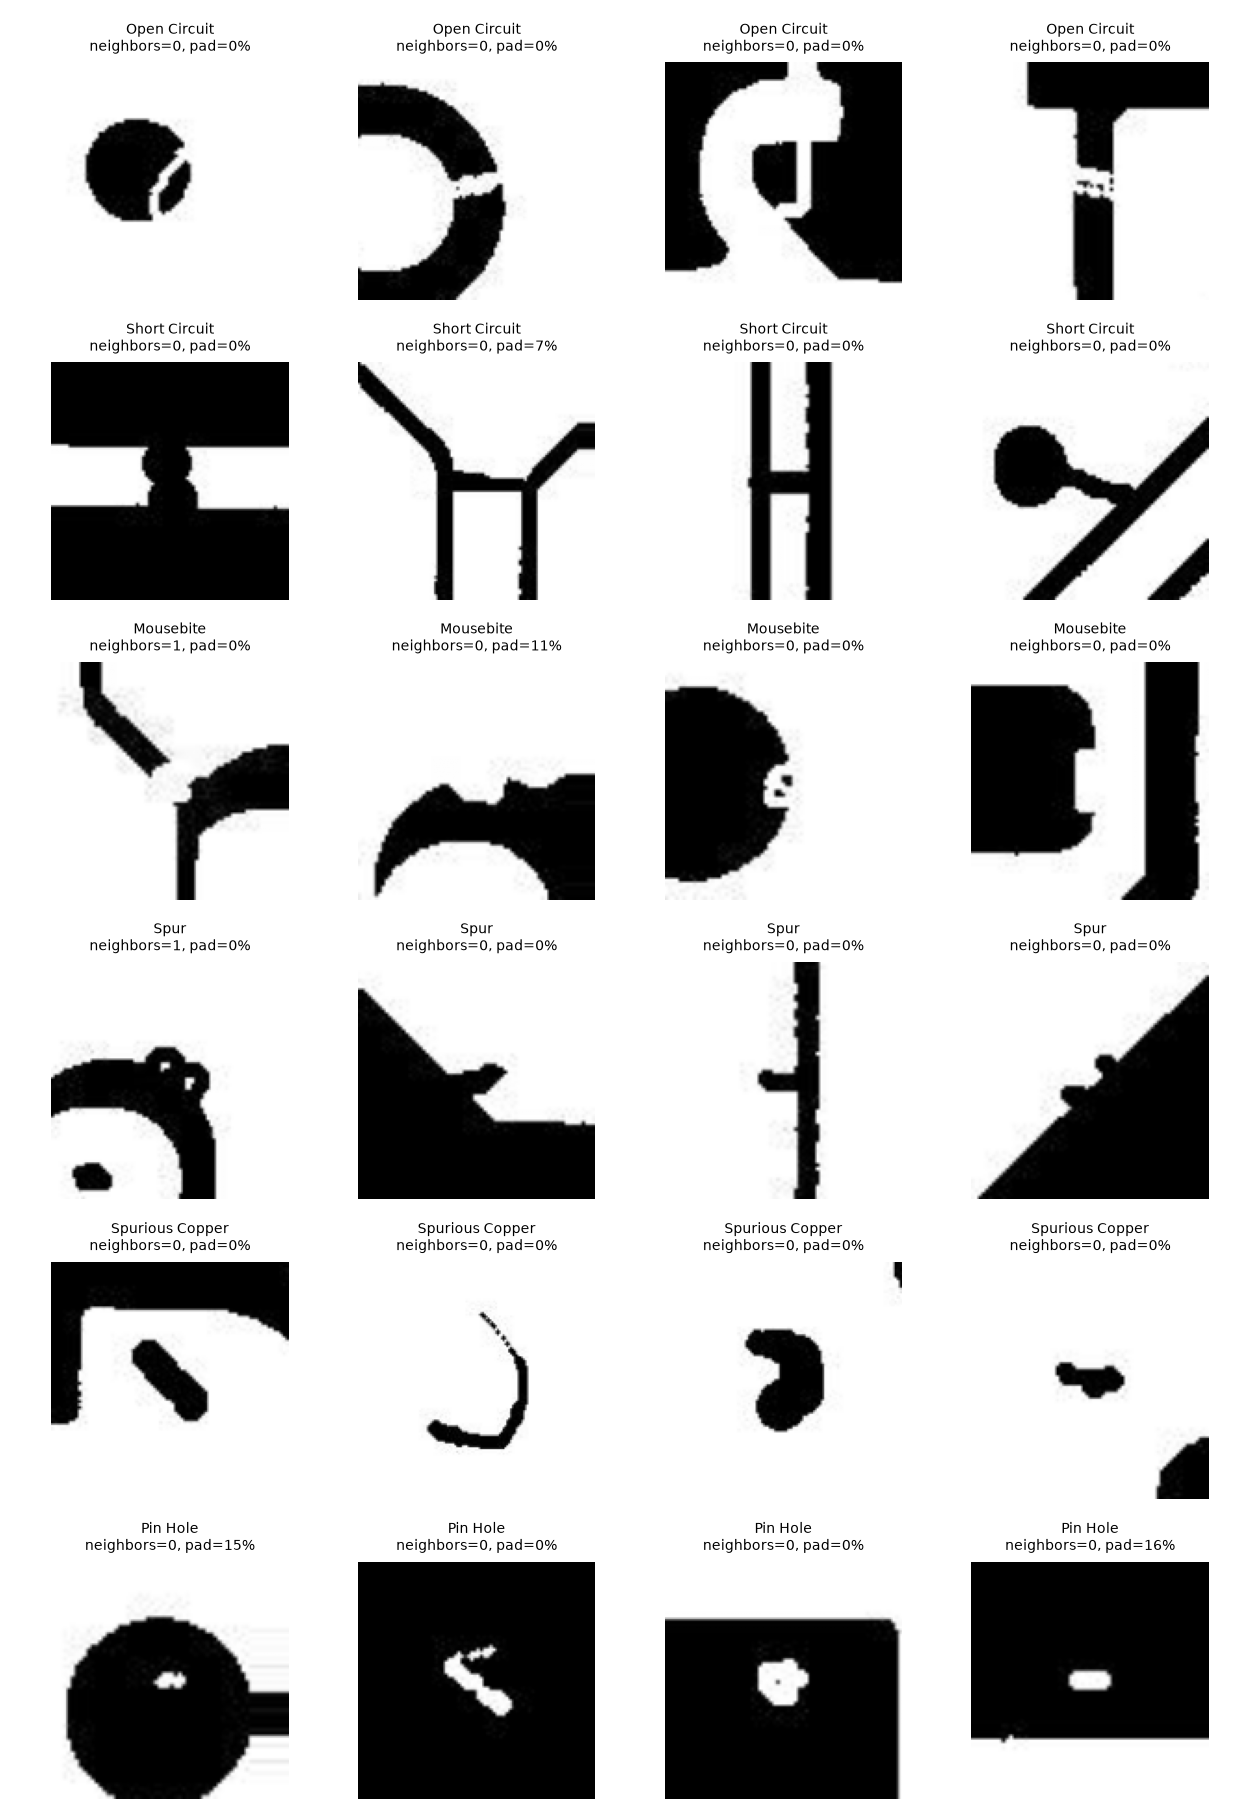

In [17]:
# 분할 잠금 → 원본 주석 재검사 → train/val Crop 저장 → 분할 간 패치 중복 검사.
from src.preprocessing import CropConfig, prepare_patches
from IPython.display import display, Image as DisplayImage
import pandas as pd

crop_config = CropConfig(size=128, margin=16, validation_group='group00041', seed=42)
preprocessing_result = prepare_patches(ROOT, crop_config)
patches = pd.read_csv(ROOT / 'data/split/patches.csv')
display(pd.crosstab(patches.class_name, patches.split))
print('테스트 패치 생성 수:', preprocessing_result['test_patches_created'])
display(DisplayImage(filename=str(ROOT / 'results/figures/processed_patches_train.png'), width=850))

## 3단계 — 기본 CNN A 학습

A는 요청한 Conv2D(32→64→128), MaxPooling, GlobalAveragePooling, Dense(64), Dropout(0.3), Softmax(6) 구조를 사용합니다. 사전학습 가중치와 증강은 사용하지 않습니다.

- Adam, batch 16, 최대 30 epoch, seed 42
- 그룹 홀드아웃 validation **Macro F1**로 checkpoint / EarlyStopping / 학습률 감소
- 입력은 0~255이며 모델 안에서 0~1로 정규화합니다.
- 동일 run_name의 완료 결과는 재사용합니다. 새 실험은 새로운 run_name을 사용하세요.
- 아래 셀은 실제 학습을 실행하며 몇 분 이상 소요될 수 있습니다.

In [18]:
# 초기 Metal graph 오류가 있었던 실행은 보존하되 모델 비교에서 제외합니다.
# 재실행 시 이 잘못된 설정으로 다시 학습하지 않습니다.
import json
from IPython.display import display
initial_run = ROOT / 'results/training/A_baseline_001/run_result.json'
if initial_run.exists():
    initial_diagnostic_result = json.loads(initial_run.read_text())
    print('A_baseline_001: 진단 전용, 모델 성능 비교에서 제외')
    display(initial_diagnostic_result)
else:
    print('초기 진단 실행 기록 없음. 아래 안전 설정의 A를 사용하세요.')

A_baseline_001: 진단 전용, 모델 성능 비교에서 제외


{'run_name': 'A_baseline_001',
 'status': 'completed',
 'metrics': {'accuracy': 0.36547231270358305,
  'precision_macro': 0.25344168053865274,
  'recall_macro': 0.4014356590133665,
  'macro_f1': 0.2830815898161878,
  'weighted_f1': 0.2613293877970862,
  'split': 'validation',
  'official_test_evaluated': False,
  'samples': 1535},
 'epochs_completed': 8,
 'best_epoch': 1,
 'elapsed_seconds': 77.10170779202599,
 'model_path': '/Users/yeongjunna/DNN_project/models/A_baseline_001/best.keras'}

### A 결과 확인 및 Metal 진단

초기 A의 Keras 기록 Accuracy와 저장 모델의 NumPy 기반 Accuracy가 일치하지 않았습니다. 학습률만 바꾸기 전에 CPU/Metal의 eager/graph 추론, Accuracy, CrossEntropy를 같은 입력으로 비교합니다. 실험 결과를 검증하기 전에는 높은 성능으로 보고하지 않습니다.

In [19]:
import json
from IPython.display import display
from pathlib import Path
import pandas as pd

# 최초 실측 진단을 보존합니다. 정상 실행 중에는 잘못된 최적화를 다시 켜지 않습니다.
diagnostic_path = ROOT / 'results/reports/metal_diagnostic.json'
if diagnostic_path.exists():
    diagnostic = json.loads(diagnostic_path.read_text())
    print('최초 Metal 진단 기록을 재표시합니다.')
    display(pd.DataFrame(diagnostic))
else:
    # 동일한 가중치와 입력으로 CPU/Metal 및 graph/eager 연산을 대조합니다.
    from src.dataset import make_dataset
    from src.evaluate import collect_predictions, scores
    from tensorflow import keras
    import json
    import numpy as np

    val_data, val_frame = make_dataset(ROOT, 'val', batch_size=16)
    x_probe, y_probe = next(iter(val_data))
    diagnostic = []
    reference = None
    for device in ['/CPU:0', '/GPU:0']:
        with tf.device(device):
            checked_model = keras.models.load_model(ROOT / 'models/A_baseline_001/best.keras', compile=False)
            for graph in [False, True]:
                forward = tf.function(lambda x: checked_model(x, training=False)) if graph else checked_model
                probabilities = forward(x_probe).numpy()
                expected_accuracy = float((probabilities.argmax(1) == y_probe.numpy()).mean())
                tensorflow_accuracy = float(tf.reduce_mean(tf.cast(tf.argmax(probabilities, 1, output_type=tf.int32) == y_probe, tf.float32)).numpy())
                numpy_loss = float(-np.log(np.clip(probabilities[np.arange(len(y_probe)), y_probe.numpy()], 1e-7, 1)).mean())
                tensorflow_loss = float(keras.losses.sparse_categorical_crossentropy(y_probe, probabilities).numpy().mean())
                if reference is None:
                    reference = probabilities.copy()
                diagnostic.append(dict(device=device, graph=graph, numpy_accuracy=expected_accuracy,
                                       tensorflow_accuracy=tensorflow_accuracy, numpy_loss=numpy_loss,
                                       tensorflow_loss=tensorflow_loss, max_prediction_delta=float(abs(reference-probabilities).max())))
    display(pd.DataFrame(diagnostic))
    (ROOT / 'results/reports/metal_diagnostic.json').write_text(json.dumps(diagnostic, indent=2))

최초 Metal 진단 기록을 재표시합니다.


,device,graph,numpy_accuracy,tensorflow_accuracy,numpy_loss,tensorflow_loss,max_prediction_delta
0,/CPU:0,False,0.5625,0.5625,1.065755,1.065755,0.000000e+00
1,/CPU:0,True,0.5625,0.5625,1.065755,1.065755,0.000000e+00
2,/GPU:0,False,0.5625,0.5625,1.065755,1.065755,1.192093e-07
3,/GPU:0,True,0.5625,0.5625,0.935669,0.935669,4.154873e-01


In [20]:
# 같은 실제 입력으로 그래프 최적화 회피 설정을 검증합니다.
from src.dataset import make_dataset
from src.model import build_model
from tensorflow import keras
val_data, val_frame = make_dataset(ROOT, 'val', batch_size=16)
x_probe, y_probe = next(iter(val_data))
tf.config.optimizer.set_experimental_options({'disable_meta_optimizer': True})
with tf.device('/GPU:0' if gpus else '/CPU:0'):
    initial_model_path = ROOT / 'models/A_baseline_001/best.keras'
    safe_model = keras.models.load_model(initial_model_path, compile=False) if initial_model_path.exists() else build_model('A')
    safe_graph = tf.function(lambda x: safe_model(x, training=False))
    safe_probabilities = safe_graph(x_probe).numpy()
    eager_probabilities = safe_model(x_probe, training=False).numpy()
safe_delta = float(abs(safe_probabilities - eager_probabilities).max())
print('그래프 최적화 비활성 후 eager/graph 최대 차이:', safe_delta)
assert safe_delta < 1e-4, 'Metal graph 결과 불일치가 남아 있어 eager 학습 또는 CPU로 전환해야 합니다.'
(ROOT / 'results/reports/metal_workaround.json').write_text(json.dumps({
    'optimizer_options': tf.config.optimizer.get_experimental_options(),
    'max_prediction_delta': safe_delta, 'verified': True
}, indent=2))

그래프 최적화 비활성 후 eager/graph 최대 차이: 0.0


154

In [21]:
# 입력/모델/학습률은 그대로 두고 검증한 Metal 실행 설정만 변경합니다.
import importlib
import src.model, src.train
importlib.reload(src.model)
importlib.reload(src.train)
from src.train import TrainingConfig, train_model

safe_baseline_config = TrainingConfig(run_name='A_baseline_safe_002', variant='A', epochs=30,
                                      batch_size=16, learning_rate=0.001, patience=7, augment=False, seed=42)
safe_baseline_result = train_model(ROOT, safe_baseline_config)
display(safe_baseline_result)

기존 완료 결과를 재사용합니다: A_baseline_safe_002


{'run_name': 'A_baseline_safe_002',
 'status': 'reused_completed_run',
 'metrics': {'accuracy': 0.6260586319218241,
  'precision_macro': 0.6462110140578855,
  'recall_macro': 0.6338109034062267,
  'macro_f1': 0.6315452033715436,
  'weighted_f1': 0.6248792473780855,
  'split': 'validation',
  'official_test_evaluated': False,
  'samples': 1535},
 'model_path': '/Users/yeongjunna/DNN_project/models/A_baseline_safe_002/best.keras'}

## 4단계 1차 — 직접 설계 CNN B 비교

A의 학습 설정을 보존하고 별도의 개선 모델을 비교합니다. B는 2회 Conv 블록(24→48→96), BatchNormalization, SpatialDropout, Flatten+Dense96(L2), Dropout(0.4)를 사용합니다. 중심 불량의 위치 관계를 보존하고 train에만 90도 회전·반전·약한 밝기 증강을 적용합니다.

고정된 그룹 검증과 같은 실행 안전 설정을 사용합니다. 이 비교는 여러 설계 변경의 전체 효과이며 개별 요소의 효과를 증명하는 ablation은 아닙니다. 공식 test는 열지 않습니다.

In [22]:
# 검증 그룹을 바꾸지 않고 직접 설계한 개선 CNN B를 비교합니다.
importlib.reload(src.model)
importlib.reload(src.train)
from src.train import TrainingConfig, train_model

improved_config = TrainingConfig(run_name='B_improved_001', variant='B', epochs=40,
                                 batch_size=16, learning_rate=0.0005, patience=10, augment=True, seed=42)
improved_result = train_model(ROOT, improved_config)
display(improved_result)

기존 완료 결과를 재사용합니다: B_improved_001


{'run_name': 'B_improved_001',
 'status': 'reused_completed_run',
 'metrics': {'accuracy': 0.9947882736156352,
  'precision_macro': 0.9947801697058795,
  'recall_macro': 0.9951290457540952,
  'macro_f1': 0.9949463198655196,
  'weighted_f1': 0.9947894831343763,
  'split': 'validation',
  'official_test_evaluated': False,
  'samples': 1535},
 'model_path': '/Users/yeongjunna/DNN_project/models/B_improved_001/best.keras'}

## 저장 모델 검증 및 1차 비교

A/B는 동일 그룹 validation을 사용합니다. 초기 Metal 오류 실험은 제외하고, 저장 checkpoint를 재로드한 지표만 비교합니다. 최고 validation 후보는 최종 test 성능을 측정한 모델이 아닙니다.

학습과 독립된 `src/predict.py`로 같은 패치를 추론해 평가 시 저장된 6개 점수와 일치하는지도 확인합니다.

In [23]:
# Metal 문제의 재발 여부를 최종 B의 전체 validation에서 CPU와 대조합니다.
from src.evaluate import collect_predictions, scores
from src.dataset import make_dataset
from tensorflow import keras

cpu_validation_data, cpu_validation_frame = make_dataset(ROOT, 'val', batch_size=16)
with tf.device('/CPU:0'):
    cpu_model = keras.models.load_model(ROOT / 'models/B_improved_001/best.keras', compile=False)
    cpu_labels, cpu_probabilities = collect_predictions(cpu_model, cpu_validation_data)
    cpu_probe_device = cpu_model(next(iter(cpu_validation_data))[0], training=False).device
saved_gpu = pd.read_csv(ROOT / 'results/training/B_improved_001/validation_predictions.csv')
assert np.array_equal(cpu_labels, saved_gpu.target_id.values)
saved_gpu_probabilities = saved_gpu[[f'score_{i}' for i in range(6)]].values
cpu_gpu_delta = float(abs(cpu_probabilities-saved_gpu_probabilities).max())
label_agreement = float((cpu_probabilities.argmax(1) == saved_gpu.predicted_target.values).mean())
assert cpu_gpu_delta < 1e-4 and label_agreement == 1.0
cpu_gpu_check = dict(samples=len(cpu_labels), cpu_device=cpu_probe_device,
                     max_score_delta=cpu_gpu_delta, prediction_agreement=label_agreement,
                     cpu_validation_metrics=scores(cpu_labels, cpu_probabilities.argmax(1)), verified=True)
(ROOT / 'results/reports/cpu_metal_validation_parity.json').write_text(json.dumps(cpu_gpu_check, indent=2))
display(cpu_gpu_check)

2026-11-18 15:19:42.693280: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


{'samples': 1535,
 'cpu_device': '/job:localhost/replica:0/task:0/device:CPU:0',
 'max_score_delta': 4.7190399166119334e-07,
 'prediction_agreement': 1.0,
 'cpu_validation_metrics': {'accuracy': 0.9947882736156352,
  'precision_macro': 0.9947801697058795,
  'recall_macro': 0.9951290457540952,
  'macro_f1': 0.9949463198655196,
  'weighted_f1': 0.9947894831343763},
 'verified': True}

,run_name,accuracy,precision_macro,recall_macro,macro_f1,weighted_f1,best_epoch
0,A_baseline_safe_002,0.626059,0.646211,0.633811,0.631545,0.624879,5
1,B_improved_001,0.994788,0.994780,0.995129,0.994946,0.994789,36


독립 추론과 저장 평가 점수 최대 차이: 1.581420883134399e-09


{'prediction': {'target_id': 2, 'name': 'Mousebite', 'korean': '패턴 가장자리 결손'},
 'softmax_score': 0.9999997615814209,
 'class_scores': {'Open Circuit': 1.218952974113563e-07,
  'Short Circuit': 3.87354148756458e-08,
  'Mousebite': 0.9999997615814209,
  'Spur': 1.664118065569653e-09,
  'Spurious Copper': 7.457838513413861e-11,
  'Pin Hole': 2.6062537017423892e-08},
 'interpretation': 'uncalibrated relative class scores; not probability of defect presence'}

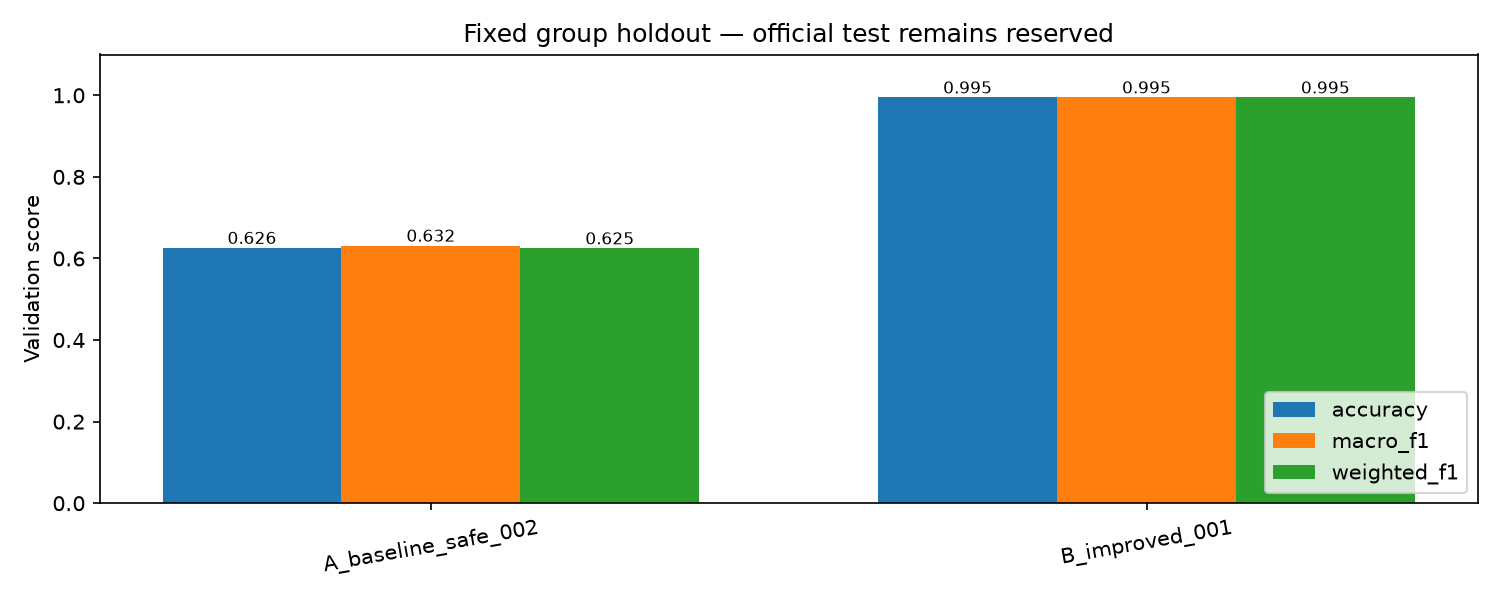

In [26]:
# 실제 완료 run만 모아 보고서/그래프를 갱신합니다.
import src.report
importlib.reload(src.report)
from src.report import write_progress_report
from src.predict import predict_patch
from PIL import Image as PILImage
from IPython.display import Markdown

comparison = write_progress_report(ROOT)
display(comparison[['run_name', 'accuracy', 'precision_macro', 'recall_macro', 'macro_f1', 'weighted_f1', 'best_epoch']])
selected = json.loads((ROOT / 'results/reports/selected_model.json').read_text())
prediction_frame = pd.read_csv(ROOT / 'results/training' / selected['run_name'] / 'validation_predictions.csv')
sample_row = prediction_frame.iloc[0]
with PILImage.open(ROOT / sample_row.patch_path) as image:
    inference_result = predict_patch(ROOT / selected['model_path'], image)
stored_scores = sample_row[[f'score_{i}' for i in range(6)]].to_numpy(dtype=float)
inference_scores = np.array(list(inference_result['class_scores'].values()))
inference_delta = float(abs(stored_scores-inference_scores).max())
assert inference_delta < 1e-4, '평가/독립 추론 간 전처리 또는 모델 실행이 다릅니다.'
print('독립 추론과 저장 평가 점수 최대 차이:', inference_delta)
display(inference_result)
(ROOT / 'results/reports/inference_smoke_test.json').write_text(json.dumps({
    'model': selected['run_name'], 'patch_id': sample_row.patch_id,
    'max_score_delta': inference_delta, 'verified': True
}, indent=2))
display(DisplayImage(filename=str(ROOT / 'results/figures/model_comparison_validation.png'), width=950))

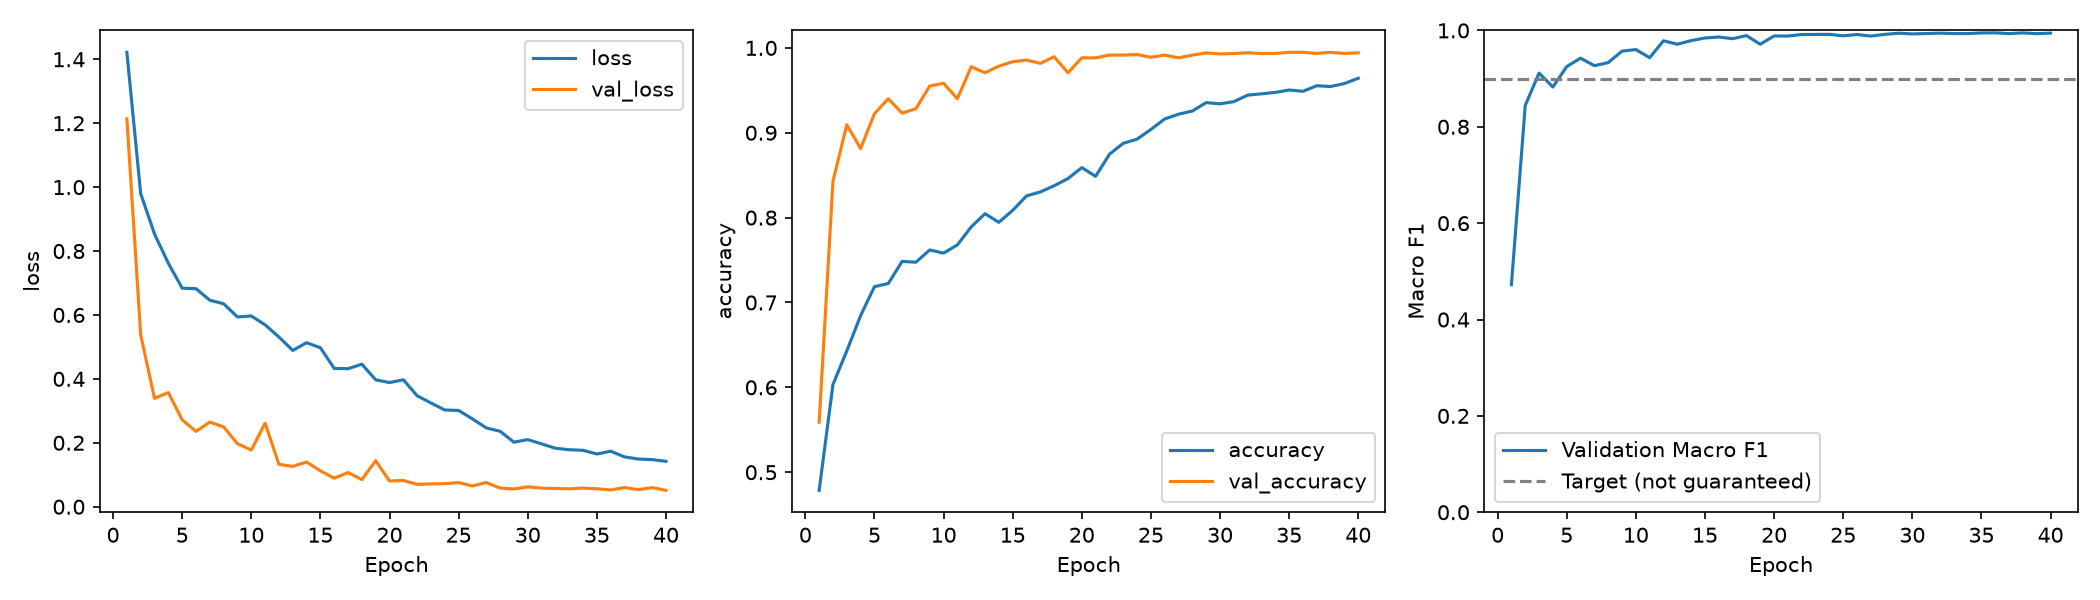

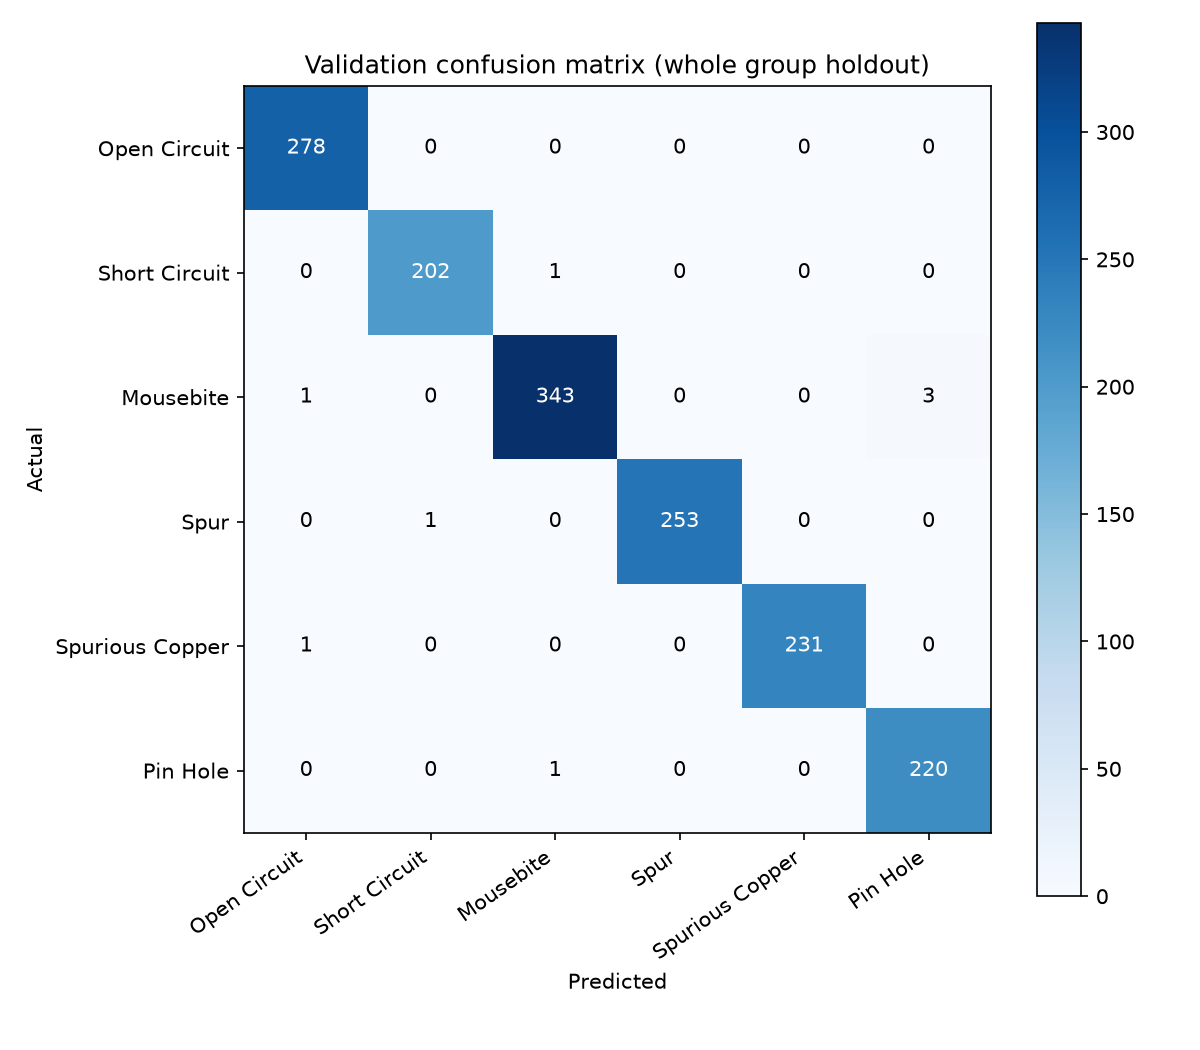

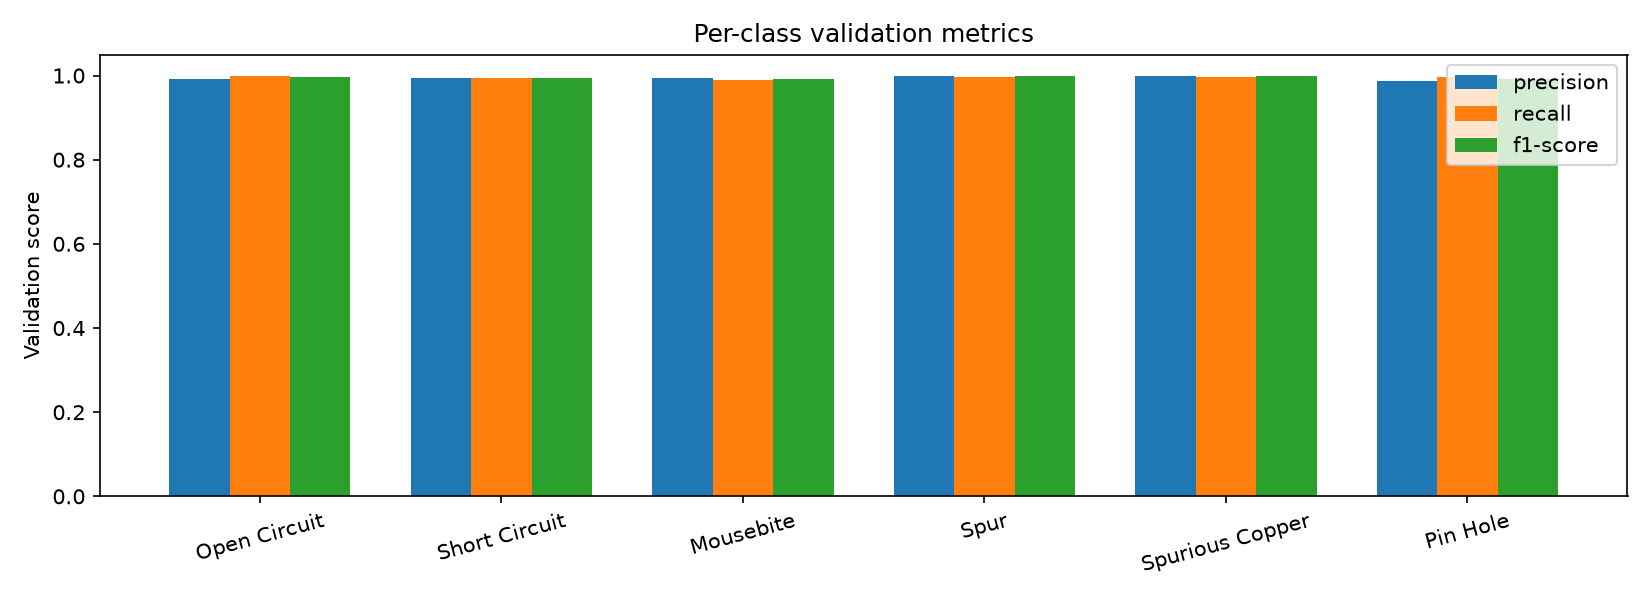

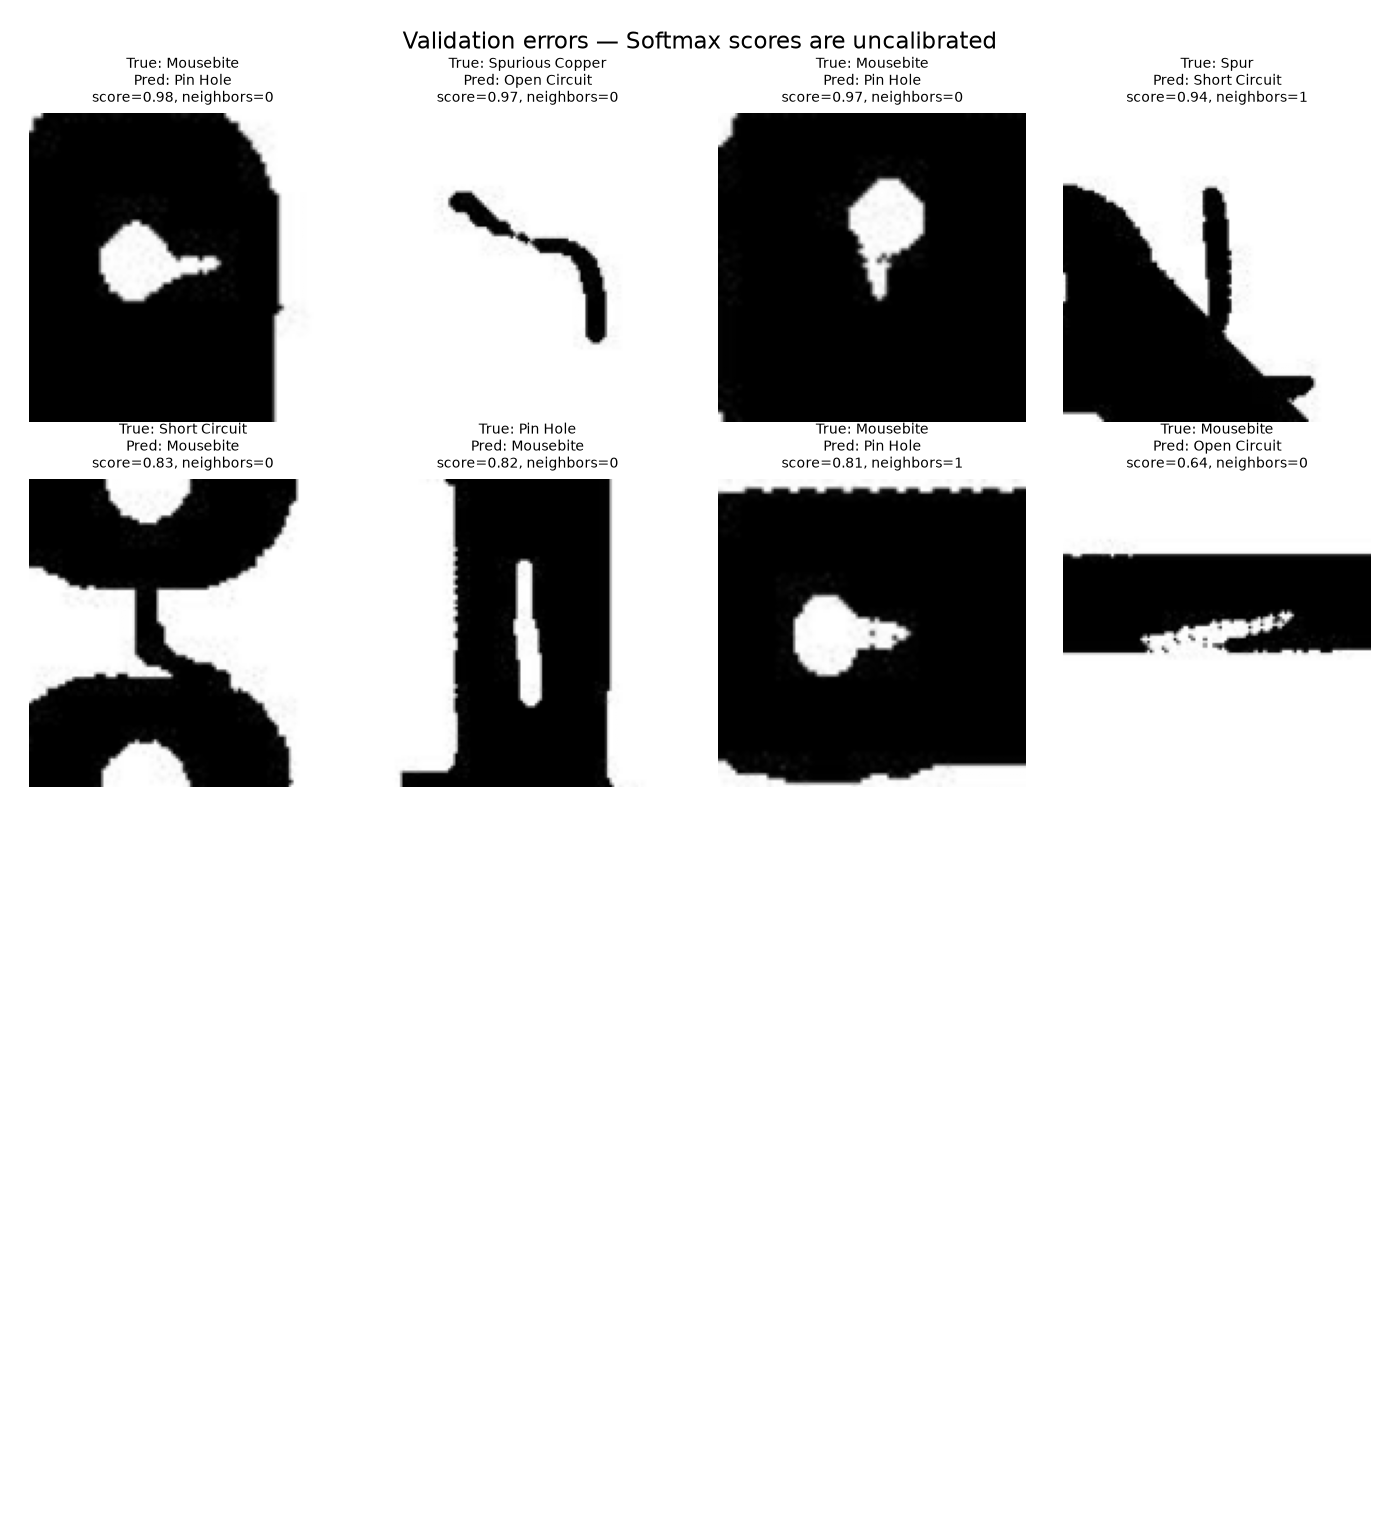

,slice,samples,accuracy,precision_macro,recall_macro,macro_f1,weighted_f1
0,no_neighbor,1260,0.995238,0.995658,0.995341,0.995492,0.995239
1,has_neighbor,275,0.992727,0.993126,0.994282,0.993641,0.992734
2,no_padding,1509,0.994698,0.994638,0.995022,0.994821,0.994700
3,has_padding,26,1.000000,0.666667,0.666667,0.666667,1.000000


# 2~3단계 전처리 및 CNN 검증 결과

## 실제 실행 범위

Python 3.11.9를 유지했다. TensorFlow 2.18.1 / Metal 1.2.0 / Keras 3.8.0 / NumPy 2.0.2를 설치했다.
M1 Pro GPU 열거와 실제 행렬 연산을 확인했고, CNN 학습과 저장 checkpoint 재로드 평가를 수행했다.
공식 test는 전처리와 모델 선택에 사용하지 않았으며 최종 성능을 아직 측정하지 않았다.

## 고정 분할 및 Crop

- train: 800개 원본 / 5338개 패치.
- validation: `group00041` 전체 200개 원본 / 1535개 패치.
- test: 공식 500쌍 예약. 생성한 test 패치 0개.
- 그룹은 성능을 보기 전 trainval의 이미지 수 20%에 가장 가까운 기준으로 고정했다.
- train/validation의 원본·그룹·정상/검사 영상 픽셀 중복 및 생성 패치의 동일 픽셀 중복을 검사했다.
- 원본 bbox 주변 16px 여백, 정사각형, edge padding, bilinear resize 128×128, grayscale PNG.
- README가 좌표 끝점의 포함 여부를 명시하지 않아 오른쪽/아래를 +1px 보수적으로 포함했다.
  원본 좌표와 반열린 ROI를 모두 manifest에 남겨 재현할 수 있다.
- 이웃 bbox가 ROI에 걸친 패치 1136개, 경계 padding 패치 264개.
  해당 표본을 삭제하지 않았고 validation 진단 결과를 각 실행의 `validation_slices.csv`에 저장했다.
- 정규화는 저장 모델의 Rescaling에서 1/255로 한 번 수행한다. 로더/추론에서 이중 정규화하지 않는다.
- 증강 사용 실험은 train에만 90도 회전/좌우/상하 반전/약한 밝기 조절을 적용한다.
  epoch마다 온라인 적용하며 증강본을 validation 또는 디스크에 추가하지 않는다.

| 유형 | train | validation |
|---|---:|---:|
| Open Circuit | 1005 | 278 |
| Short Circuit | 825 | 203 |
| Mousebite | 1032 | 347 |
| Spur | 888 | 254 |
| Spurious Copper | 778 | 232 |
| Pin Hole | 810 | 221 |

## Metal 실행 오류와 수정 근거

초기 `A_baseline_001`은 Keras graph Accuracy와 NumPy eager Accuracy가 달랐다.
같은 가중치·입력에서 CPU eager/graph 및 Metal eager는 약 1e-7 이내로 일치했으나,
Metal graph는 최대 약 0.415의 점수 차이가 있었다. 초기 실험은 성능 비교에서 제외했다.
`tf.config.optimizer.set_experimental_options({"disable_meta_optimizer": True})`를 적용한
후 진단 batch의 Metal graph/eager 출력 차이는 0이었다. GPU 사용은 유지했다.

이 결과는 현재 장비·설치 조합에서의 재현 관찰이며 다른 모든 TensorFlow/Metal 조합의 오류를 주장하지 않는다.
근거는 `metal_diagnostic.json`, `metal_workaround.json`, 초기 실행의 `history.csv`다.
수정 후 매 epoch마다 graph Keras Accuracy와 eager/NumPy Accuracy 차이가 1e-4보다 크면 즉시 실패하도록 했다.
학습/독립 추론 함수 모두 같은 회피 설정을 적용한다.

최종 B의 validation 1535개 전체를 CPU에서 다시 추론했다. Metal 평가와 예측 라벨 일치율은 100.00%, 6개 점수의 최대 절대 차이는 4.72e-07였다. 실측 기록은 `cpu_metal_validation_parity.json`에 저장했다.

## 검증 성능 (공식 test 성능 아님)

| 실행 | Accuracy | Macro F1 | Weighted F1 | 최고 epoch |
|---|---:|---:|---:|---:|
| A_baseline_safe_002 | 0.6261 | 0.6315 | 0.6249 | 5 |
| B_improved_001 | 0.9948 | 0.9949 | 0.9948 | 36 |

현재 validation Macro F1 기준 후보는 **B_improved_001 / 0.9949**다.
모든 지표는 동일 고정 그룹에서 측정했으며 최대 검증 F1의 checkpoint를 파일에서 다시 불러와 평가했다.
이 검증 집합은 모델 선택에도 쓰였으므로 독립적인 최종 일반화 성능으로 해석하지 않는다.
기판/인접 타일 유사도 전체를 배제한 것은 아니며 공식 trainval/test의 그룹 겹침 제한도 남아 있다.

현재 후보의 validation 오분류는 **8 / 1535개**다. 많이 관측된 혼동은 다음과 같다.

- Mousebite → Pin Hole: 3개
- Mousebite → Open Circuit: 1개
- Pin Hole → Mousebite: 1개
- Short Circuit → Mousebite: 1개
- Spur → Short Circuit: 1개

train 지표는 증강과 Dropout이 켜진 상태, validation 지표는 둘 다 꺼진 상태이므로
validation 점수가 train보다 높다는 사실만으로 누수나 평가 오류로 단정하지 않는다.
검증 그룹 자체의 난이도도 다를 수 있다. 이웃/패딩 slice는 클래스 구성과 표본 수가 다르며
특히 작은 slice의 Macro F1 차이를 단독 원인으로 해석하지 않는다.
slice의 Macro F1은 고정된 6종 ID를 기준으로 계산해 그 slice에 없는 클래스도 0으로 포함한다.
따라서 4종만 존재하는 padding slice는 전부 정답이어도 Macro F1이 4/6이며,
이 값과 전체 validation Macro F1을 단순 비교해서는 안 된다.

오분류 시각 검토에서는 Mousebite→Pin Hole 사례의 흰색 영역이 Crop 안에서 구멍처럼 보였다.
이는 모양에 대한 관찰이며 라벨 오류를 확정한 것은 아니다. 원본/정상 기준 영상과 대조하는
수동 검토 후보로 기록하고, 현재 검증 라벨이나 평가 표본은 수정/삭제하지 않았다.

Model A는 요청된 기본 CNN(32→64→128, GAP, Dense64, Dropout0.3)이다.
Model B는 2회 합성곱 블록(24→48→96), BatchNormalization, SpatialDropout, Flatten,
Dense96의 L2 규제와 Dropout0.4를 사용해 중심 불량의 위치 관계를 유지한다.
ImageNet 가중치는 A/B에서 사용하지 않는다. 여러 요소를 동시에 바꾼 A/B 비교만으로
개별 요소의 인과 효과를 주장하지 않는다. Model C 전이학습 비교는 후속 단계다.

## 저장 파일과 후속 작업

- `data/split/`: 잠긴 설정, 원본별 split, train/val 패치 manifest, 예약된 test 메타데이터.
- `data/processed/roi128_v1/`: 실제 train/val PNG 패치.
- `models/<run>/best.keras`, `metadata.json`: 최고 checkpoint와 클래스/정규화 계약.
- `results/training/<run>/`: 설정, 실행 환경, epoch 로그, 학습 곡선, Accuracy/Precision/Recall/Macro·Weighted F1,
  클래스별 보고서, 혼동행렬, 전체 예측, 오분류 이미지/목록, 이웃/패딩 진단.
- `src/predict.py`: 학습 코드와 분리된 단일 패치 추론. 6종 결함의 상대 점수이며 정상 판별/불량 탐지가 아니다.

후속에는 A/B의 오분류와 표본 모호성을 검토하고, 필요 시 문맥 크기 한 가지씩 비교한다.
Model C와 추가 그룹 검증 후 설정을 확정한 뒤 공식 test를 최초 최종 평가한다.
Streamlit은 그 뒤에 실제 검증된 모델과 보고서를 연결한다.

## 참고 문서

- [Apple tensorflow-metal](https://developer.apple.com/metal/tensorflow-plugin/)
- [TensorFlow 그래프 최적화 설정](https://www.tensorflow.org/api_docs/python/tf/config/optimizer/set_experimental_options)
- [DeepPCB 주석 형식](https://github.com/tangsanli5201/DeepPCB)


In [27]:
# 학습 곡선, 혼동행렬, 클래스 지표와 오분류는 모두 validation 결과입니다.
selected_output = ROOT / 'results/training' / selected['run_name']
for filename in ['learning_curves.png', 'confusion_matrix.png', 'class_metrics.png', 'misclassified.png']:
    display(DisplayImage(filename=str(selected_output / filename), width=950))
display(pd.read_csv(selected_output / 'validation_slices.csv'))
display(Markdown((ROOT / 'results/reports/training_progress_report.md').read_text(encoding='utf-8')))